In [1]:
import sys

import matplotlib
import numpy
import pandas
import sklearn

print(sys.version.split()[0], numpy.__version__, pandas.__version__, sklearn.__version__, matplotlib.__version__)

3.12.5 2.3.4 2.3.3 1.7.2 3.10.7


In [2]:
import numpy as np
import pandas as pd
from sklearn.model_selection import StratifiedKFold, train_test_split

SEED = 3194          # last 4 digits of my student ID
data = pd.read_csv("data/spambase.csv")
feature_names = [c for c in data.columns if c != "spam"]
X, y = data[feature_names].to_numpy(), data["spam"].to_numpy()
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, stratify=y, random_state=SEED)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
print(X.shape, round(100 * y.mean(), 1), X_train.shape, X_test.shape)

(4204, 57) 39.9 (3153, 57) (1051, 57)


**SEED = 3194** (last 4 digits of my student ID)

# Task 4 — Random Forests & Ensembles (Smakov)

## Fixed models

In [3]:
from sklearn.base import clone
from sklearn.ensemble import AdaBoostClassifier, BaggingClassifier, RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import FunctionTransformer, StandardScaler
from sklearn.tree import DecisionTreeClassifier

tree = DecisionTreeClassifier(random_state=SEED)
bag = BaggingClassifier(DecisionTreeClassifier(), n_estimators=100, oob_score=True, random_state=SEED)
rf = RandomForestClassifier(n_estimators=300, oob_score=True, random_state=SEED, n_jobs=-1)
lr = make_pipeline(FunctionTransformer(np.log1p), StandardScaler(), LogisticRegression(max_iter=2000))
bag_lr = BaggingClassifier(lr, n_estimators=50, random_state=SEED)
knn = make_pipeline(FunctionTransformer(np.log1p), StandardScaler(), KNeighborsClassifier(n_neighbors=15))
ada = AdaBoostClassifier(n_estimators=400, random_state=SEED)
members = [("lr", lr), ("knn", knn), ("tree", tree)]   # members of voting and stacking in Parts 3-4
print("models defined")

models defined


## Part 1
Bagging and out-of-bag estimates

In [4]:
def oob_mask(sample_indices, n_samples):
    """Boolean mask of the rows that do NOT occur in sample_indices."""
    import numpy as np
    mask = np.ones(int(n_samples), dtype=bool)
    idx = np.asarray(sample_indices, dtype=int).ravel()
    if idx.size > 0:
        mask[idx] = False
    return mask

In [5]:
assert oob_mask([0, 2, 2], 5).tolist() == [False, True, False, True, True]
assert oob_mask([], 3).tolist() == [True, True, True]
assert oob_mask(np.array([3, 0]), 4).tolist() == [False, True, True, False]
assert oob_mask([0, 2, 2], 5).dtype == bool and oob_mask([], 3).shape == (3,)
print("oob_mask: all examples pass")

oob_mask: all examples pass


In [6]:
bag.fit(X_train, y_train)
n = X_train.shape[0]

oob_shares = np.array([oob_mask(s, n).mean() for s in bag.estimators_samples_])
mean_oob = oob_shares.mean()
p_not_drawn = (1 - 1 / n) ** n

print(f"n (training rows)            = {n}")
print(f"mean out-of-bag share        = {mean_oob:.4f}")
print(f"mean in-bag share            = {1 - mean_oob:.4f}")
print(f"formula (1 - 1/n)^n          = {p_not_drawn:.4f}")
print(f"formula 1 - (1 - 1/n)^n      = {1 - p_not_drawn:.4f}")

n (training rows)            = 3153
mean out-of-bag share        = 0.3675
mean in-bag share            = 0.6325
formula (1 - 1/n)^n          = 0.3678
formula 1 - (1 - 1/n)^n      = 0.6322


In [7]:
votes = np.zeros((n, 2))
for est, s in zip(bag.estimators_, bag.estimators_samples_):
    m = oob_mask(s, n)
    pred = est.predict(X_train[m]).astype(int)
    votes[np.where(m)[0], pred] += 1

oob_pred = np.argmax(votes, axis=1)          # tie -> class 0
oob_acc = (oob_pred == y_train).mean()
print(f"rows with no OOB vote: {(votes.sum(axis=1) == 0).sum()}")
print(f"OOB accuracy by hand : {oob_acc:.6f}")
print(f"bag.oob_score_       : {bag.oob_score_:.6f}")

rows with no OOB vote: 0
OOB accuracy by hand : 0.933714
bag.oob_score_       : 0.933714


In [8]:
from sklearn.model_selection import cross_validate

all_scores = {}   # fold scores of every model on the same cv folds (reused in Parts 3, 4, 6)

def cv_scores(name, model):
    s = cross_validate(model, X_train, y_train, cv=cv, scoring="accuracy")["test_score"]
    all_scores[name] = s
    return s

def cv_table(names):
    rows = {}
    for nm in names:
        s = all_scores[nm]
        rows[nm] = list(s) + [s.mean(), np.std(s)]
    cols = [f"fold {i+1}" for i in range(5)] + ["mean", "std"]
    return pd.DataFrame.from_dict(rows, orient="index", columns=cols).round(4)

def paired_table(pairs):
    rows = {}
    for a, b in pairs:
        d = all_scores[a] - all_scores[b]
        m, s = d.mean(), np.std(d)
        rows[f"{a} - {b}"] = list(d) + [m, s, "inside spread" if abs(m) <= s else "outside spread"]
    cols = [f"fold {i+1}" for i in range(5)] + ["mean", "std", "verdict"]
    df = pd.DataFrame.from_dict(rows, orient="index", columns=cols)
    num = cols[:7]
    df[num] = df[num].astype(float).round(4)
    return df

In [9]:
for name, model in [("tree", tree), ("bag", bag), ("rf", rf), ("lr", lr), ("bag_lr", bag_lr)]:
    cv_scores(name, model)

display(cv_table(["tree", "bag", "rf", "lr", "bag_lr"]))
display(paired_table([("bag", "tree"), ("rf", "tree"), ("bag_lr", "lr")]))

,fold 1,fold 2,fold 3,fold 4,fold 5,mean,std
tree,0.9128,0.9113,0.9113,0.8889,0.8778,0.9004,0.0144
bag,0.9382,0.9319,0.9493,0.9127,0.9238,0.9312,0.0124
rf,0.9525,0.9334,0.9620,0.9317,0.9397,0.9439,0.0116
lr,0.9239,0.9239,0.9461,0.9206,0.9365,0.9302,0.0096
bag_lr,0.9239,0.9239,0.9461,0.9238,0.9365,0.9309,0.0091


,fold 1,fold 2,fold 3,fold 4,fold 5,mean,std,verdict
bag - tree,0.0254,0.0206,0.0380,0.0238,0.0460,0.0308,0.0097,outside spread
rf - tree,0.0396,0.0222,0.0507,0.0429,0.0619,0.0435,0.0131,outside spread
bag_lr - lr,0.0000,0.0000,0.0000,0.0032,0.0000,0.0006,0.0013,inside spread


In [10]:
rf.fit(X_train, y_train)
n_test = len(y_test)
p_rf = rf.score(X_test, y_test)
se_rf = np.sqrt(p_rf * (1 - p_rf) / n_test)
rf_cv = all_scores["rf"]

print(f"rf.oob_score_      = {rf.oob_score_:.4f}")
print(f"rf CV mean (step 3) = {rf_cv.mean():.4f}   (fold std = {np.std(rf_cv):.4f})")
print(f"rf test accuracy p  = {p_rf:.4f}   SE = {se_rf:.4f}   (p ± SE: {p_rf - se_rf:.4f} … {p_rf + se_rf:.4f})")
print(f"|oob - cv mean|     = {abs(rf.oob_score_ - rf_cv.mean()):.4f}  -> "
      f"{'agree' if abs(rf.oob_score_ - rf_cv.mean()) <= np.std(rf_cv) else 'do not agree'}")

rf.oob_score_      = 0.9445
rf CV mean (step 3) = 0.9439   (fold std = 0.0116)
rf test accuracy p  = 0.9553   SE = 0.0064   (p ± SE: 0.9489 … 0.9617)
|oob - cv mean|     = 0.0006  -> agree


### Part 1 results

**OOB share.** There are n = 3153 training rows. The mean OOB share over 100 trees is 0.3675 and the in-bag share is 0.6325. The formula gives (1 - 1/n)^n = 0.3678 and 1 - (1 - 1/n)^n = 0.6322, so my numbers are very close to it. Each tree does not see about 37% of the rows.

**OOB accuracy by hand.** Every row got at least one OOB vote. My OOB accuracy is 0.933714 and bag.oob_score_ is 0.933714, they are the same.

**(a)** For the tree, bag - tree = 0.0308 ± 0.0097. Bagging was better on all 5 folds and |mean| > std, so the difference is outside the fold spread and bagging improves the tree (0.9004 -> 0.9312). Random forest is even better, rf - tree = 0.0435 ± 0.0131, also outside the spread. The reason is that a full decision tree has high variance: if the training rows change a little, the tree changes a lot. Bagging trains many trees on different bootstrap samples and takes the vote, so the errors of single trees partly cancel and the variance goes down. Random forest also picks random features at each split, so the trees are less similar and averaging works even better.

For logistic regression, bag_lr - lr = 0.0006 ± 0.0013, and on 4 folds the difference is exactly 0. |mean| <= std, so it is inside the fold spread and my data cannot show that bagging changes logistic regression. Logistic regression is a stable model with low variance, so the 50 bootstrap models are almost the same as the original one and averaging them gives almost the same predictions. Bagging reduces variance, not bias, so it helps unstable models like trees but not this one.

**(b)** rf.oob_score_ = 0.9445 and the CV mean = 0.9439. The difference is 0.0006, smaller than the std of the rf fold scores (0.0116), so by the task rule they agree and OOB is a fair replacement for CV here. It also needs no extra fitting. The test accuracy is p = 0.9553 with SE = 0.0064. Both OOB and CV are a bit lower than the test accuracy, by about 0.011 (around 1.7 SE). This gap is smaller than the fold std, so it can be just the noise of one test split. OOB and CV are also expected to be a little pessimistic: in OOB each row is predicted by only about 37% of the trees, and in CV each model is trained on 80% of the training rows, while the final forest uses all 3153 rows.

## Part 2
Evaluating the filter: curves, a threshold, importances

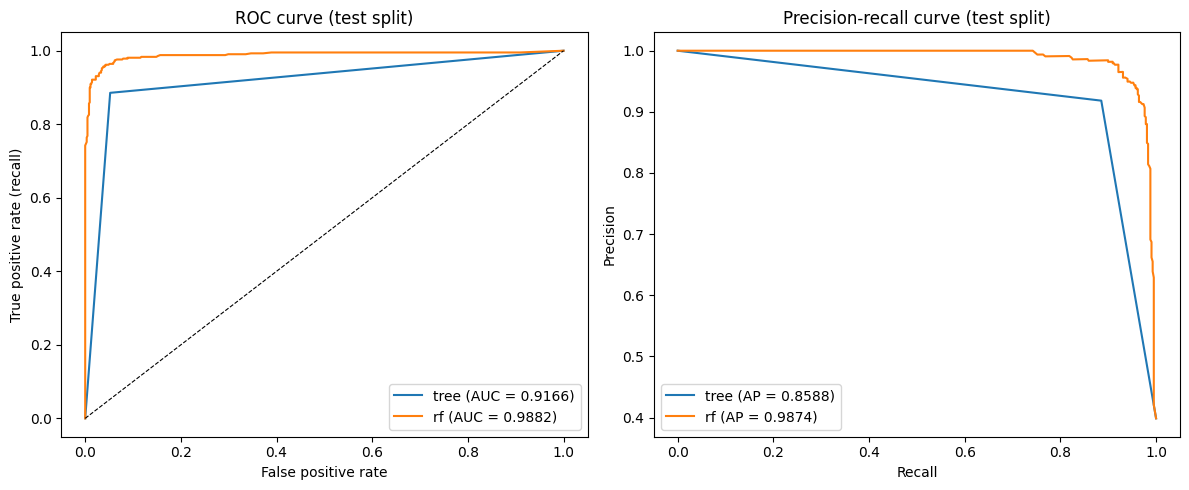

In [14]:
import matplotlib.pyplot as plt
from sklearn.metrics import (roc_curve, precision_recall_curve, roc_auc_score,
                             average_precision_score, confusion_matrix)

tree_fit = clone(tree).fit(X_train, y_train)
test_proba = {"tree": tree_fit.predict_proba(X_test)[:, 1],
              "rf": rf.predict_proba(X_test)[:, 1]}

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for name, p in test_proba.items():
    fpr_c, tpr_c, _ = roc_curve(y_test, p)
    axes[0].plot(fpr_c, tpr_c, label=f"{name} (AUC = {roc_auc_score(y_test, p):.4f})")
    prec_c, rec_c, _ = precision_recall_curve(y_test, p)
    axes[1].plot(rec_c, prec_c, label=f"{name} (AP = {average_precision_score(y_test, p):.4f})")
axes[0].plot([0, 1], [0, 1], "k--", lw=0.8)
axes[0].set(xlabel="False positive rate", ylabel="True positive rate (recall)", title="ROC curve (test split)")
axes[1].set(xlabel="Recall", ylabel="Precision", title="Precision-recall curve (test split)")
axes[0].legend(); axes[1].legend()
plt.tight_layout()
plt.show()

In [15]:
from sklearn.model_selection import cross_val_predict

oof = cross_val_predict(rf, X_train, y_train, cv=cv, method="predict_proba")[:, 1]
fpr_o, tpr_o, thr_o = roc_curve(y_train, oof, drop_intermediate=False)

ok = fpr_o <= 0.01                       # thresholds with OOF FPR at most 1%
best_recall = tpr_o[ok].max()
t = thr_o[ok & (tpr_o == best_recall)].max()   # if tie in recall, take the largest threshold

flag_oof = oof >= t
print(f"t = {t!r}")
print(f"OOF FPR at t    = {flag_oof[y_train == 0].mean():.4f}")
print(f"OOF recall at t = {flag_oof[y_train == 1].mean():.4f}")

t = np.float64(0.7533333333333333)
OOF FPR at t    = 0.0095
OOF recall at t = 0.7979


In [16]:
flag_test = (test_proba["rf"] >= t).astype(int)
cm = confusion_matrix(y_test, flag_test, labels=[0, 1])
display(pd.DataFrame(cm, index=["true legit (0)", "true spam (1)"],
                     columns=["predicted legit (0)", "predicted spam (1)"]))

tn, fp, fn, tp = cm.ravel()
print(f"precision = {tp / (tp + fp):.4f}")
print(f"recall    = {tp / (tp + fn):.4f}")
print(f"FPR       = {fp / (fp + tn):.4f}")
print(f"{fp} of {fp + tn} legitimate test mails were flagged as spam")

,predicted legit (0),predicted spam (1)
true legit (0),629,3
true spam (1),91,328


precision = 0.9909
recall    = 0.7828
FPR       = 0.0047
3 of 632 legitimate test mails were flagged as spam


In [17]:
from sklearn.inspection import permutation_importance

perm = permutation_importance(rf, X_test, y_test, n_repeats=10, random_state=SEED, scoring="accuracy")
imp = pd.DataFrame({"impurity": rf.feature_importances_,
                    "permutation": perm.importances_mean}, index=feature_names)
imp["impurity rank"] = imp["impurity"].rank(ascending=False).astype(int)
imp["permutation rank"] = imp["permutation"].rank(ascending=False, method="min").astype(int)

print("Top 5 by impurity importance (rf.feature_importances_):")
display(imp.sort_values("impurity", ascending=False).head(5).round(4))
print("Top 5 by permutation importance (test split):")
display(imp.sort_values("permutation", ascending=False).head(5).round(4))

Top 5 by impurity importance (rf.feature_importances_):


,impurity,permutation,impurity rank,permutation rank
char_freq_exclam,0.1205,0.0136,1,3
char_freq_dollar,0.0919,0.0069,2,5
word_freq_remove,0.0761,0.0277,3,1
word_freq_free,0.0686,0.0059,4,7
capital_run_length_average,0.0614,0.0024,5,10


Top 5 by permutation importance (test split):


,impurity,permutation,impurity rank,permutation rank
word_freq_remove,0.0761,0.0277,3,1
word_freq_hp,0.0479,0.0204,9,2
char_freq_exclam,0.1205,0.0136,1,3
word_freq_george,0.0197,0.0076,14,4
char_freq_dollar,0.0919,0.0069,2,5


### Part 2 results

**Curves.** On the test split the forest is much better than the single tree: ROC AUC 0.9882 vs 0.9166 and average precision 0.9874 vs 0.8588. The tree gives almost only 0/1 probabilities, so its curves have just one corner point.

**Threshold.** Using only the out-of-fold probabilities on the training split, the threshold with the highest recall and OOF FPR <= 0.01 is t = 0.7533, with OOF FPR = 0.0095 and OOF recall = 0.7979.

**Test split (applied once).** Confusion matrix: 629 legit predicted legit, 3 legit predicted spam, 91 spam predicted legit, 328 spam predicted spam. Precision = 0.9909, recall = 0.7828, FPR = 0.0047. 3 of 632 legitimate test mails were flagged as spam, so the 1% target held on the test split. Recall is close to the OOF recall. The price is that about 22% of spam gets through. Only 3 legit mails were flagged, so the test FPR is a bit noisy (1% of 632 would be about 6 mails).

**Importances.** char_freq_exclam, word_freq_remove and char_freq_dollar are in both top 5, but the order differs. For example capital_run_length_average is rank 5 by impurity importance (0.0614) but only rank 10 by permutation importance (0.0024). Impurity importance is computed on the training data and sums how much a feature reduced the Gini impurity over all splits. Continuous features with many different values can be used in many splits, so they collect a lot of impurity decrease, even from splits that only fit the training data. Permutation importance shuffles one feature on the test split and measures the drop in accuracy. capital_run_length_average is strongly related to capital_run_length_longest and capital_run_length_total, so when it is shuffled the forest can still use the other two and accuracy almost does not drop.

## Part 3
Voting

In [18]:
def hard_vote(predictions, weights=None):
    """Weighted majority vote of several models' predicted labels, one label per sample."""
    import numpy as np
    P = np.asarray(predictions, dtype=int)
    if P.ndim != 2 or P.size == 0:
        n_samples = P.shape[1] if P.ndim == 2 else 0
        return np.zeros(n_samples, dtype=int)
    n_models, n_samples = P.shape
    w = np.ones(n_models, dtype=int) if weights is None else np.asarray(weights)
    count_dtype = np.int64 if w.dtype.kind in "biu" else np.float64
    counts = np.zeros((P.max() + 1, n_samples), dtype=count_dtype)
    cols = np.arange(n_samples)
    for m in range(n_models):             # add weights in model order
        counts[P[m], cols] += w[m]
    return np.argmax(counts, axis=0).astype(int)   # first max = smallest label

In [19]:
assert hard_vote([[0, 1, 1], [0, 1, 0], [1, 1, 0]]).tolist() == [0, 1, 0]
assert hard_vote([[0, 1], [1, 0]]).tolist() == [0, 0]
assert hard_vote([[0, 1], [1, 0]], weights=[1, 2]).tolist() == [1, 0]
assert hard_vote([[2, 0], [2, 1], [0, 1]]).tolist() == [2, 1]
assert hard_vote([[0, 1], [1, 0]], weights=[0, 0]).tolist() == [0, 0]
r = hard_vote([[0, 1, 1]])
assert r.shape == (3,) and r.dtype.kind == "i"
print("hard_vote: all examples pass")

hard_vote: all examples pass


In [20]:
from sklearn.ensemble import VotingClassifier

member_pred = {}
for name, model in members:
    member_pred[name] = clone(model).fit(X_train, y_train).predict(X_test)
pred_stack = np.vstack([member_pred[name] for name, _ in members])   # shape (3, n_test)
print("shape:", pred_stack.shape)

my_vote = hard_vote(pred_stack)
sk_vote = VotingClassifier(members, voting="hard").fit(X_train, y_train).predict(X_test)
print(f"agreement hard_vote vs VotingClassifier: {(my_vote == sk_vote).mean():.4f}")

shape: (3, 1051)
agreement hard_vote vs VotingClassifier: 1.0000


In [21]:
pairs = [("lr", "knn"), ("lr", "tree"), ("knn", "tree")]
dis = pd.DataFrame({"pair": [f"{a} vs {b}" for a, b in pairs],
                    "disagreement": [(member_pred[a] != member_pred[b]).mean() for a, b in pairs]})
display(dis.round(4))

,pair,disagreement
0,lr vs knn,0.0504
1,lr vs tree,0.0752
2,knn vs tree,0.0894


In [22]:
cv_scores("knn", knn)
cv_scores("hard", VotingClassifier(members, voting="hard"))
cv_scores("soft", VotingClassifier(members, voting="soft"))

display(cv_table(["lr", "knn", "tree", "hard", "soft"]))
best_member = max(["lr", "knn", "tree"], key=lambda nm: all_scores[nm].mean())
print("best member:", best_member)
display(paired_table([("hard", best_member), ("soft", best_member)]))

,fold 1,fold 2,fold 3,fold 4,fold 5,mean,std
lr,0.9239,0.9239,0.9461,0.9206,0.9365,0.9302,0.0096
knn,0.9097,0.9097,0.9287,0.9095,0.9286,0.9172,0.0093
tree,0.9128,0.9113,0.9113,0.8889,0.8778,0.9004,0.0144
hard,0.9303,0.9223,0.9493,0.9270,0.9444,0.9347,0.0104
soft,0.9382,0.9303,0.9556,0.9206,0.9238,0.9337,0.0125


best member: lr


,fold 1,fold 2,fold 3,fold 4,fold 5,mean,std,verdict
hard - lr,0.0063,-0.0016,0.0032,0.0063,0.0079,0.0044,0.0034,outside spread
soft - lr,0.0143,0.0063,0.0095,0.0000,-0.0127,0.0035,0.0093,inside spread


### Part 3 results

**Reproducing scikit-learn.** My hard_vote and VotingClassifier(voting="hard") give the same label on all test rows (agreement = 1.0000).

**Disagreement.** lr vs knn = 0.0504, lr vs tree = 0.0752, knn vs tree = 0.0894. The members make different mistakes on 5-9% of the test mails, so there is something for the vote to fix. The tree is the most different from the other two.

**Cross-validation.** The best member is lr with mean 0.9302. Hard voting has mean 0.9347 and soft voting 0.9337.

**Hard voting.** hard - lr = 0.0044 ± 0.0034. It is better on 4 of 5 folds and |mean| > std, so the difference is outside the fold spread and by the task rule hard voting beats the best member. The gain is small (about 0.4 percentage points). It works because when one member is wrong, the other two often outvote it.

**Soft voting.** soft - lr = 0.0035 ± 0.0093. The fold differences go from -0.0127 to +0.0143, and |mean| <= std, so it is inside the fold spread. My data cannot separate soft voting from logistic regression, so I do not name a winner. One possible reason is that the tree gives only 0 or 1 probabilities. In the average it acts as a very confident member and can pull the result to the wrong side, which hurt on fold 5.

## Part 4
Stacking

In [23]:
from sklearn.ensemble import StackingClassifier

member_names = [name for name, _ in members]

# out-of-fold probabilities of spam on the training split
Z_train = np.column_stack([
    cross_val_predict(m, X_train, y_train, cv=cv, method="predict_proba")[:, 1] for _, m in members])
meta = LogisticRegression().fit(Z_train, y_train)

# members fitted on the full training split -> test matrix
fitted_members = [clone(m).fit(X_train, y_train) for _, m in members]
Z_test = np.column_stack([fm.predict_proba(X_test)[:, 1] for fm in fitted_members])
my_stack_pred = meta.predict(Z_test)

stack = StackingClassifier(members, LogisticRegression(), cv=cv).fit(X_train, y_train)
sk_stack_pred = stack.predict(X_test)

print("my meta coef :", meta.coef_[0].round(6))
print("sklearn coef :", stack.final_estimator_.coef_[0].round(6))
print(f"largest |coef difference|  = {np.abs(meta.coef_ - stack.final_estimator_.coef_).max():.2e}")
print("test predictions identical:", np.array_equal(my_stack_pred, sk_stack_pred))
print(f"my stacking test accuracy  = {(my_stack_pred == y_test).mean():.4f}")
print(f"stack.score(X_test, y_test) = {stack.score(X_test, y_test):.4f}")

my meta coef : [3.86389  2.452587 1.700052]
sklearn coef : [3.86389  2.452587 1.700052]
largest |coef difference|  = 0.00e+00
test predictions identical: True
my stacking test accuracy  = 0.9524
stack.score(X_test, y_test) = 0.9524


In [24]:
Z_naive = np.column_stack([fm.predict_proba(X_train)[:, 1] for fm in fitted_members])
meta_naive = LogisticRegression().fit(Z_naive, y_train)

coef_table = pd.DataFrame({"naive (in-sample)": meta_naive.coef_[0],
                           "out-of-fold": meta.coef_[0]}, index=member_names)
display(coef_table.round(4))
print(f"intercept: naive = {meta_naive.intercept_[0]:.4f}, out-of-fold = {meta.intercept_[0]:.4f}")
print(f"tree in-sample accuracy on training rows = {(fitted_members[2].predict(X_train) == y_train).mean():.4f}")

,naive (in-sample),out-of-fold
lr,1.9023,3.8639
knn,1.8150,2.4526
tree,8.3410,1.7001


intercept: naive = -6.0500, out-of-fold = -3.9524
tree in-sample accuracy on training rows = 1.0000


In [25]:
cv_scores("stack", StackingClassifier(members, LogisticRegression(), cv=cv))

display(cv_table([best_member, "soft", "stack"]))
display(paired_table([("stack", best_member), ("stack", "soft")]))

,fold 1,fold 2,fold 3,fold 4,fold 5,mean,std
lr,0.9239,0.9239,0.9461,0.9206,0.9365,0.9302,0.0096
soft,0.9382,0.9303,0.9556,0.9206,0.9238,0.9337,0.0125
stack,0.9366,0.9271,0.9493,0.9302,0.9397,0.9366,0.0078


,fold 1,fold 2,fold 3,fold 4,fold 5,mean,std,verdict
stack - lr,0.0127,0.0032,0.0032,0.0095,0.0032,0.0063,0.0040,outside spread
stack - soft,-0.0016,-0.0032,-0.0063,0.0095,0.0159,0.0029,0.0084,inside spread


### Part 4 results

**Comparison with StackingClassifier.** My out-of-fold stacking gives the same meta-learner coefficients as stack.final_estimator_.coef_ (lr 3.8639, knn 2.4526, tree 1.7001, largest difference 0.0). The test predictions are identical and both test accuracies are 0.9524.

**(a) Tree weight, naive vs out-of-fold.** With naive stacking the tree gets the biggest weight, 8.3410, but with out-of-fold stacking only 1.7001, the smallest of the three. The reason is that the full tree memorizes the training rows: its in-sample accuracy is 1.0000, so its in-sample probabilities are exactly the labels. The meta-learner sees a "perfect" member and puts almost all trust in it. On new data the tree is the weakest member (CV mean 0.9004), so this weight is wrong. Out-of-fold probabilities come from models that did not see these rows, so they show how good each member really is on unseen mails. Then lr, the best member, gets the largest weight.

**(b) Cross-validation.** stack - lr = 0.0063 ± 0.0040. Stacking is better on all 5 folds and |mean| > std, so the difference is outside the fold spread and stacking beats the best member. stack - soft = 0.0029 ± 0.0084, with fold differences from -0.0063 to +0.0159, so |mean| <= std and it is inside the fold spread. My data cannot separate stacking from soft voting, so I do not name a winner between them.

## Part 5
AdaBoost and label noise

In [26]:
def adaboost_step(y_true, y_pred, weights):
    """One AdaBoost round: return (alpha, new_weights) for a learner's predictions and the current row weights."""
    import math
    import numpy as np
    yt = np.asarray(y_true)
    yp = np.asarray(y_pred)
    w = np.array(weights, dtype=float)       # copy, the argument is not changed
    wrong = yp != yt
    total = w.sum()
    eps = w[wrong].sum() / total
    if eps == 0:
        return math.inf, w / total
    alpha = math.log((1 - eps) / eps)
    w[wrong] = w[wrong] * math.exp(alpha)
    return float(alpha), w / w.sum()

In [27]:
import math

def check(call, alpha_exp, w_exp):
    a, w_new = call
    assert (a == alpha_exp) if math.isinf(alpha_exp) else math.isclose(a, alpha_exp, abs_tol=1e-12)
    assert np.allclose(w_new, w_exp) and isinstance(w_new, np.ndarray) and w_new.dtype == float

check(adaboost_step([1, 1, 0, 0], [1, 0, 0, 0], [1, 1, 1, 1]), math.log(3), [1/6, 1/2, 1/6, 1/6])
check(adaboost_step([1, 1, 1, 0], [0, 0, 0, 0], [1, 1, 1, 1]), -math.log(3), [1/6, 1/6, 1/6, 1/2])
check(adaboost_step([1, 0], [0, 0], [1, 1]), 0.0, [0.5, 0.5])
check(adaboost_step([1, 0, 1], [1, 0, 1], [2, 2, 4]), math.inf, [0.25, 0.25, 0.5])
check(adaboost_step([-1, 1, 1, -1], [-1, 1, -1, -1], [0.1, 0.2, 0.1, 0.1]), math.log(4), [0.125, 0.25, 0.5, 0.125])

w_arg = np.array([0.1, 0.2, 0.1, 0.1]); adaboost_step([-1, 1, 1, -1], [-1, 1, -1, -1], w_arg)
assert w_arg.tolist() == [0.1, 0.2, 0.1, 0.1]     # argument not modified
print("adaboost_step: all examples pass")

adaboost_step: all examples pass


In [28]:
x       = np.arange(1, 11)
y_toy   = np.array([1, 1, 1, 0, 0, 0, 1, 1, 1, 0])
stump_1 = np.where(x <= 3.5, 1, 0)      # 1 if x <= 3.5, else 0
stump_2 = np.where(x <= 9.5, 1, 0)      # 1 if x <= 9.5, else 0
stump_3 = np.where(x <= 6.5, 0, 1)      # 0 if x <= 6.5, else 1

w_toy = np.full(10, 0.1)
for k, stump in enumerate([stump_1, stump_2, stump_3], start=1):
    wrong = stump != y_toy
    eps = w_toy[wrong].sum() / w_toy.sum()
    alpha, w_toy = adaboost_step(y_toy, stump, w_toy)
    print(f"stump {k}: wrong rows x = {x[wrong].tolist()}, eps = {eps:.3f}, alpha = {alpha:.3f}")
    print(f"         new weights = {np.round(w_toy, 3).tolist()}")

stump 1: wrong rows x = [7, 8, 9], eps = 0.300, alpha = 0.847
         new weights = [0.071, 0.071, 0.071, 0.071, 0.071, 0.071, 0.167, 0.167, 0.167, 0.071]
stump 2: wrong rows x = [4, 5, 6], eps = 0.214, alpha = 1.299
         new weights = [0.045, 0.045, 0.045, 0.167, 0.167, 0.167, 0.106, 0.106, 0.106, 0.045]
stump 3: wrong rows x = [1, 2, 3, 10], eps = 0.182, alpha = 1.504
         new weights = [0.125, 0.125, 0.125, 0.102, 0.102, 0.102, 0.065, 0.065, 0.065, 0.125]


In [29]:
ada.fit(X_train, y_train)

w_ada = np.full(n, 1 / n)
rows = []
for rnd in range(5):
    pred = ada.estimators_[rnd].predict(X_train)
    eps = w_ada[pred != y_train].sum() / w_ada.sum()
    alpha, w_ada = adaboost_step(y_train, pred, w_ada)
    rows.append([rnd, eps, ada.estimator_errors_[rnd], alpha, ada.estimator_weights_[rnd]])

check_df = pd.DataFrame(rows, columns=["round", "my eps", "sklearn eps", "my alpha", "sklearn alpha"])
display(check_df)
print(f"largest |alpha difference| = {np.abs(check_df['my alpha'] - check_df['sklearn alpha']).max():.2e}")
print(f"largest |eps difference|   = {np.abs(check_df['my eps'] - check_df['sklearn eps']).max():.2e}")

,round,my eps,sklearn eps,my alpha,sklearn alpha
0,0,0.211862,0.211862,1.313740,1.313740
1,1,0.246707,0.246707,1.116255,1.116255
2,2,0.286388,0.286388,0.912994,0.912994
3,3,0.287787,0.287787,0.906155,0.906155
4,4,0.347656,0.347656,0.629357,0.629357


largest |alpha difference| = 4.44e-16
largest |eps difference|   = 5.55e-17


In [30]:
train_err = 1 - np.array(list(ada.staged_score(X_train, y_train)))
test_err = 1 - np.array(list(ada.staged_score(X_test, y_test)))
rounds = np.arange(1, len(test_err) + 1)
print("number of rounds:", len(rounds))

number of rounds: 400


In [31]:
curves = []
for tr_idx, va_idx in cv.split(X_train, y_train):
    a = clone(ada).fit(X_train[tr_idx], y_train[tr_idx])
    curves.append(np.array(list(a.staged_score(X_train[va_idx], y_train[va_idx]))))
print("curve lengths:", [len(c) for c in curves])
mean_cv_acc = np.mean(curves, axis=0)

chosen_round = int(np.argmax(mean_cv_acc)) + 1           # smallest round if tie
test_best_round = int(np.argmin(test_err)) + 1            # smallest round if tie
err_chosen = test_err[chosen_round - 1]
err_best = test_err[test_best_round - 1]
p_chosen = 1 - err_chosen
se_chosen = np.sqrt(p_chosen * (1 - p_chosen) / n_test)

print(f"chosen round (CV on train)  = {chosen_round}, mean CV accuracy = {mean_cv_acc[chosen_round - 1]:.4f}")
print(f"test error at chosen round  = {err_chosen:.4f}")
print(f"lowest test error round     = {test_best_round}, test error = {err_best:.4f}")
print(f"difference = {err_chosen - err_best:.4f}, SE at chosen round = {se_chosen:.4f} -> "
      f"{'differ by more than SE' if abs(err_chosen - err_best) > se_chosen else 'not more than SE'}")

curve lengths: [400, 400, 400, 400, 400]
chosen round (CV on train)  = 387, mean CV accuracy = 0.9391
test error at chosen round  = 0.0514
lowest test error round     = 241, test error = 0.0495
difference = 0.0019, SE at chosen round = 0.0068 -> not more than SE


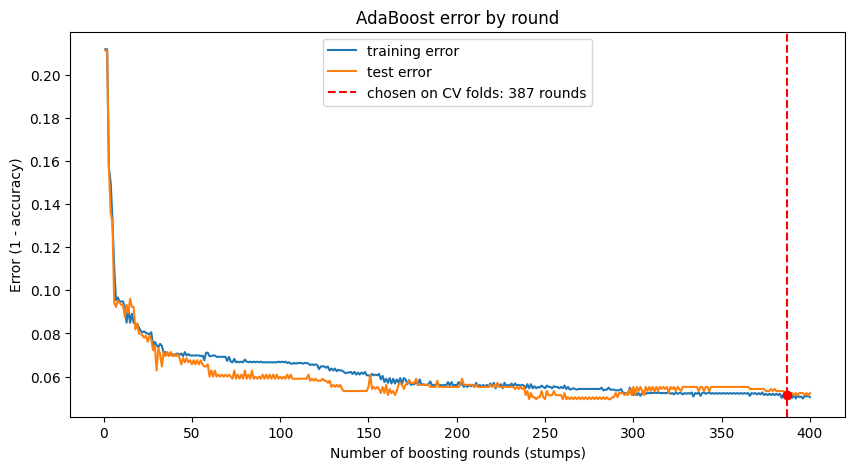

In [34]:
plt.figure(figsize=(10, 5))
plt.plot(rounds, train_err, label="training error")
plt.plot(rounds, test_err, label="test error")
plt.axvline(chosen_round, color="red", linestyle="--", label=f"chosen on CV folds: {chosen_round} rounds")
plt.scatter([chosen_round], [err_chosen], color="red", zorder=3)
plt.xlabel("Number of boosting rounds (stumps)")
plt.ylabel("Error (1 - accuracy)")
plt.title("AdaBoost error by round")
plt.legend()
plt.show()

In [32]:
def flip_labels(y, rate, seed):
    rng = np.random.default_rng(seed)
    idx = rng.choice(len(y), size=round(rate * len(y)), replace=False)
    y_noisy = y.copy()
    y_noisy[idx] = 1 - y_noisy[idx]
    return y_noisy, idx

In [33]:
ada200 = AdaBoostClassifier(n_estimators=200, random_state=SEED)
noise_models = {"tree": tree, "rf": rf, "ada200": ada200}

clean_acc = {nm: clone(m).fit(X_train, y_train).score(X_test, y_test) for nm, m in noise_models.items()}
noisy_acc = {nm: [] for nm in noise_models}
flipped_share = []

for r in range(5):
    y_noisy, idx = flip_labels(y_train, 0.20, SEED + r)
    for nm, m in noise_models.items():
        fitted = clone(m).fit(X_train, y_noisy)
        noisy_acc[nm].append(fitted.score(X_test, y_test))
        if nm == "ada200":
            w_fin = np.full(n, 1 / n)
            for stump in fitted.estimators_:
                _, w_fin = adaboost_step(y_noisy, stump.predict(X_train), w_fin)
            flipped_share.append(w_fin[idx].sum())

loss = {nm: clean_acc[nm] - np.array(noisy_acc[nm]) for nm in noise_models}
noise_table = pd.DataFrame({
    nm: {"acc 0%": clean_acc[nm],
         "acc 20% mean": np.mean(noisy_acc[nm]), "acc 20% std": np.std(noisy_acc[nm]),
         "loss mean": loss[nm].mean(), "loss std": np.std(loss[nm]),
         **{f"loss draw {r}": loss[nm][r] for r in range(5)}}
    for nm in noise_models}).T
display(noise_table.round(4))

# paired loss differences by draw
prow = {}
for a_, b_ in [("ada200", "rf"), ("ada200", "tree"), ("tree", "rf")]:
    d = loss[a_] - loss[b_]
    prow[f"loss {a_} - loss {b_}"] = list(d.round(4)) + [round(d.mean(), 4), round(np.std(d), 4),
                                                       "inside spread" if abs(d.mean()) <= np.std(d) else "outside spread"]
display(pd.DataFrame.from_dict(prow, orient="index",
                               columns=[f"draw {r}" for r in range(5)] + ["mean", "std", "verdict"]))

flipped_share = np.array(flipped_share)
print("share of final AdaBoost weight on flipped rows, per draw:", flipped_share.round(4).tolist())
print(f"mean ± std = {flipped_share.mean():.4f} ± {np.std(flipped_share):.4f}")
print(f"share of flipped rows before the first round = {len(idx) / len(y_train):.4f}")

,acc 0%,acc 20% mean,acc 20% std,loss mean,loss std,loss draw 0,loss draw 1,loss draw 2,loss draw 3,loss draw 4
tree,0.9229,0.7307,0.0126,0.1922,0.0126,0.1798,0.1922,0.1884,0.2160,0.1846
rf,0.9553,0.9104,0.0098,0.0449,0.0098,0.0333,0.0333,0.0561,0.0485,0.0533
ada200,0.9448,0.9174,0.0037,0.0274,0.0037,0.0266,0.0266,0.0228,0.0266,0.0343


,draw 0,draw 1,draw 2,draw 3,draw 4,mean,std,verdict
loss ada200 - loss rf,-0.0067,-0.0067,-0.0333,-0.0219,-0.0190,-0.0175,0.0101,outside spread
loss ada200 - loss tree,-0.1532,-0.1656,-0.1656,-0.1893,-0.1503,-0.1648,0.0138,outside spread
loss tree - loss rf,0.1465,0.1589,0.1323,0.1675,0.1313,0.1473,0.0143,outside spread


share of final AdaBoost weight on flipped rows, per draw: [0.3911, 0.4018, 0.3976, 0.3896, 0.3861]
mean ± std = 0.3933 ± 0.0057
share of flipped rows before the first round = 0.2001


### Part 5 results

**Three rounds from the lecture.** Round 1: eps = 0.300, alpha = 0.847, weights 0.071 on the right rows and 0.167 on the wrong rows (x = 7, 8, 9), the same as on the slide. Round 2: eps = 0.214, alpha = 1.299, the wrong rows x = 4, 5, 6 go up to 0.167. Round 3: eps = 0.182, alpha = 1.504, the wrong rows x = 1, 2, 3, 10 go up to 0.125. These match the slide.

**Check against scikit-learn.** For the first five stumps of ada, the largest difference is 4.44e-16 for alpha (estimator_weights_) and 5.55e-17 for eps (estimator_errors_), so my update is the same as scikit-learn's up to floating-point rounding.

**(a) Number of rounds.** Choosing on the CV folds of the training split gives 387 rounds (mean CV accuracy 0.9391). The test error at 387 rounds is 0.0514. The lowest test error is at round 241, 0.0495. The difference is 0.0019, which is smaller than the SE of the test accuracy at round 387 (0.0068), so the two are not really different. After about 250 rounds both curves are almost flat and only move by a few mails, so the exact best round is mostly noise. AdaBoost did not clearly overfit here: the test error does not go up at the end.

**(b) Label noise.** The tree loses the most: 0.9229 -> 0.7307, loss = 0.1922 ± 0.0126. The forest loses 0.0449 ± 0.0098 and AdaBoost only 0.0274 ± 0.0037. Pairing the losses by draw: tree - rf = 0.1473 ± 0.0143, ada200 - rf = -0.0175 ± 0.0101, ada200 - tree = -0.1648 ± 0.0138. All three are outside the spread. The order tree > rf > ada200 holds on every draw, so it is bigger than the noise between draws.

The mechanism: a full tree grows until every training row is fit, so it also learns all 631 flipped labels, each one becomes its own small leaf and test mails that land there get the wrong class. The forest also has full trees that memorize the noise, but the flipped rows are random and each tree sees a different bootstrap sample, so the vote cancels part of it. AdaBoost does focus on the wrong labels: at the end the flipped rows hold 0.3933 ± 0.0057 of the total weight, almost twice their starting share of 0.2001. But each learner is only a stump with one split, and 200 stumps cannot fit hundreds of random single rows. So the extra weight on the flipped rows did not turn into memorizing them, and the ensemble still mostly follows the real pattern. In this setup the low capacity of the stumps mattered more than AdaBoost's focus on hard rows.